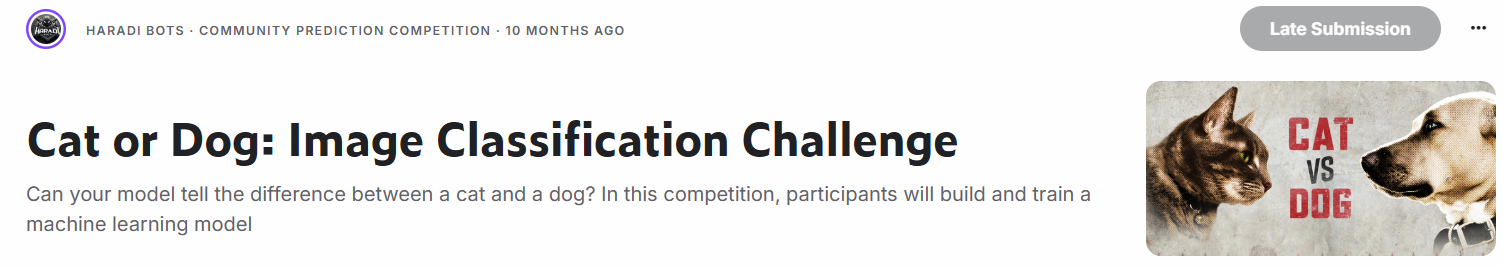

In [3]:
from sklearn import set_config
set_config(display="text")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

from sklearn.model_selection import train_test_split   #---- 문제답 분리

import tensorflow as tf
tf.random.set_seed(1234)
np.random.seed(1234)
    
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D  #---- CNN
from keras.layers import Dense, Flatten        #---- FC

In [5]:
from IPython.display import FileLink
import pandas as pd


import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
        
# 파일을 현재 작업 디렉토리(Working Directory)로 복사 또는 저장
df = pd.read_csv('/kaggle/input/handmade-metadata/metaData.csv')
df.to_csv('my_metadata.csv', index=False)

# 다운로드 링크 생성
FileLink('my_metadata.csv')

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/handmade-metadata/metaData.csv'

# **Data Load**

In [9]:
import os
import pandas as pd
from IPython.display import FileLink

# 1. 현재 주피터 노트북이 있는 폴더 주변의 모든 파일을 뒤집니다.
found_csv_files = []

# '.'은 현재 주피터 노트북이 실행 중인 폴더를 뜻합니다.
for dirname, _, filenames in os.walk('../datas/catdog_mixed'):
    for filename in filenames:
        # csv 파일 확장자를 가진 모든 파일을 검색합니다.
        if filename.endswith('.csv'):
            full_path = os.path.join(dirname, filename)
            found_csv_files.append(full_path)
            print(f"📄 찾은 CSV 파일: {full_path}")

# 2. 찾은 CSV 파일이 있다면 첫 번째 파일을 자동으로 로드합니다.
if found_csv_files:
    # 가장 먼저 발견된 csv 파일을 읽어옵니다.
    target_file = found_csv_files[0]
    print(f"\n🎯 자동으로 [{target_file}] 파일을 읽어옵니다.")
    
    df = pd.read_csv(target_file)
    
    # 데이터가 잘 들어왔는지 데이터프레임 구조 확인
    print("\n📊 데이터 상위 5개 행 미리보기:")
    print(df.head())
    
    # 현재 작업 폴더에 복사본 저장 후 다운로드 링크 생성
    df.to_csv('my_metadata.csv', index=False)
    print("\n✅ 복사본 저장 완료!")
    display(FileLink('my_metadata.csv'))
    
else:
    print("\n❌ 현재 폴더 및 하위 폴더에서 .csv 파일을 하나도 찾지 못했습니다.")
    print("💡 다운로드받은 데이터셋 압축 파일(.zip)을 풀어서 현재 주피터 노트북 폴더 안에 넣어주세요!")



❌ 현재 폴더 및 하위 폴더에서 .csv 파일을 하나도 찾지 못했습니다.
💡 다운로드받은 데이터셋 압축 파일(.zip)을 풀어서 현재 주피터 노트북 폴더 안에 넣어주세요!


In [10]:
import numpy as np
import pandas as pd
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input, decode_predictions
from tensorflow.keras.preprocessing import image

# 1. 모델과 이전에 만든 CSV 로드
model = MobileNetV2(weights='imagenet')  # ImageNet으로 학습된 기본 모델
df = pd.read_csv('my_metadata.csv')

predicted_labels = []

print("🔄 이미지 분석을 시작합니다 (시간이 다소 걸릴 수 있습니다)...")

for idx, row in df.iterrows():
    try:
        # 이미지 불러오기 및 MobileNetV2 규격(224x224)으로 크기 조정
        img = image.load_img(row['File_Path'], target_size=(224, 224))
        x = image.img_to_array(img)
        x = np.expand_dims(x, axis=0)
        
        # 앞서 배운 MobileNet 전처리 필수 적용! ([-1, 1] 스케일링)
        x = preprocess_input(x)
        
        # 예측 및 후처리 (가장 확률이 높은 상위 1개 클래스명 추출)
        preds = model.predict(x, verbose=0)
        decoded = decode_predictions(preds, top=1)[0][0] # (id, label_name, prob)
        
        label_name = decoded[1] # 클래스 영문명 추출 (예: 'goldfish', 'poodle')
        predicted_labels.append(label_name)
        
    except Exception as e:
        predicted_labels.append('Error') # 깨진 이미지 처리

# 2. 추출한 예측값으로 Label 컬럼 업데이트 후 저장
df['Label'] = predicted_labels
df.to_csv('my_metadata.csv', index=False)

print("✅ 모든 이미지의 모델 예측값으로 Label을 채웠습니다!")
print(df.head())


14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
🔄 이미지 분석을 시작합니다 (시간이 다소 걸릴 수 있습니다)...
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ 모든 이미지의 모델 예측값으로 Label을 채웠습니다!
  File_Name                       File_Path         Label
0     0.jpg     ../datas/catdog_mixed\0.jpg  Newfoundland
1     1.jpg     ../datas/catdog_mixed\1.jpg  Egyptian_cat
2    10.jpg    ../datas/catdog_mixed\10.jpg  Egyptian_cat
3   100.jpg   ../datas/catdog_mixed\100.jpg    schipperke
4  1000.jpg  ../datas/catdog_mixed\1000.jpg  bull_mastiff
